<a href="https://colab.research.google.com/github/a940203669-arch/Application-Python/blob/main/202614987%EA%B9%80%EC%86%8C%EC%97%B0_titanic_Data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("yasserh/titanic-dataset")

print("Path to dataset files:", path)

# 1. 라이브러리 설치 및 불러오기

In [ ]:
# 필요한 라이브러리 불러오기
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# 2. Titanic 데이터 불러오기 및 탐색

In [ ]:
# 데이터 파일 업로드
uploaded = files.upload()

# 데이터 불러오기 (업로드된 파일명으로 수정)
df = pd.read_csv('Titanic-Dataset.csv')

# 데이터 기본 정보 확인
print("데이터 크기:")
print(df.shape)

print("\n데이터 상위 5개:")
display(df.head())

print("\n데이터 정보:")
df.info()

print("\n기초 통계:")
display(df.describe())

# 결측치 확인
print("\n결측치 개수:")
print(df.isnull().sum())

# 3. 데이터 결측치 및 특성 생성

In [6]:
class TitanicFeatureEngineer(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):

        X = X.copy()

        # Age의 전체 중앙값
        self.age_median_ = X['Age'].median()

        # Pclass와 Sex 그룹별 Age 중앙값
        self.age_group_medians_ = (
            X.groupby(['Pclass', 'Sex'])['Age'].median()
        )

        # Embarked 최빈값
        self.embarked_mode_ = X['Embarked'].mode()[0]

        # Fare 중앙값
        self.fare_median_ = X['Fare'].median()

        return self

    def transform(self, X):

        X = X.copy()

        # Cabin 결측 여부 변수 생성
        X['Has_Cabin'] = X['Cabin'].notnull().astype(int)

        # Age 결측치 처리
        for index in X.index:

            if pd.isnull(X.loc[index, 'Age']):

                key = (
                    X.loc[index, 'Pclass'],
                    X.loc[index, 'Sex']
                )

                if key in self.age_group_medians_.index:
                    X.loc[index, 'Age'] = self.age_group_medians_[key]

                else:
                    X.loc[index, 'Age'] = self.age_median_

        # Embarked 결측치 처리
        X['Embarked'] = X['Embarked'].fillna(
            self.embarked_mode_
        )

        # Fare 결측치 처리
        X['Fare'] = X['Fare'].fillna(
            self.fare_median_
        )

        # 가족 규모 생성
        X['Family_Size'] = X['SibSp'] + X['Parch'] + 1

        # 가족 규모 구분
        def family_category(size):

            if size == 1:
                return 'Alone'

            elif size <= 3:
                return 'Small'

            elif size <= 5:
                return 'Medium'

            else:
                return 'Large'

        X['Family_Category'] = X['Family_Size'].apply(
            family_category
        )

        # 이름에서 호칭 추출
        X['Title'] = X['Name'].str.extract(
            r',\s*([^\.]+)\.',
            expand=False
        )

        # 드문 호칭 통합
        title_mapping = {
            'Mr': 'Mr',
            'Miss': 'Miss',
            'Mrs': 'Mrs',
            'Master': 'Master'
        }

        X['Title'] = X['Title'].map(
            lambda x: title_mapping.get(x, 'Rare')
        )

        # Pclass를 범주형으로 변환
        X['Pclass'] = X['Pclass'].astype(str)

        # 불필요한 원본 변수 제거
        X = X.drop(
            columns=[
                'PassengerId',
                'Name',
                'Ticket',
                'Cabin'
            ]
        )

        return X

# 4. 입력 변수와 정답 변수 분리

In [7]:
# 입력 데이터 X
X = df.drop('Survived', axis=1)

# 정답 데이터 y
y = df['Survived']

print("X 데이터 크기:", X.shape)
print("y 데이터 크기:", y.shape)

print("\n생존자 비율:")
print(y.value_counts(normalize=True))

X 데이터 크기: (891, 11)
y 데이터 크기: (891,)

생존자 비율:
Survived
0    0.616162
1    0.383838
Name: proportion, dtype: float64


# 5. One-Hot Encoding 및 StandardScaler

In [8]:
# 수치형 변수
numeric_features = [
    'Age',
    'Fare',
    'SibSp',
    'Parch',
    'Family_Size',
    'Has_Cabin'
]

# 범주형 변수
categorical_features = [
    'Sex',
    'Embarked',
    'Pclass',
    'Title',
    'Family_Category'
]

# 수치형 데이터: StandardScaler
numeric_transformer = StandardScaler()

# 범주형 데이터: One-Hot Encoding
categorical_transformer = OneHotEncoder(
    handle_unknown='ignore'
)

# 전처리 구성
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

# 전체 Pipeline 구성
pipeline = Pipeline(
    steps=[
        ('feature_engineering', TitanicFeatureEngineer()),
        ('preprocessing', preprocessor),
        ('knn', KNeighborsClassifier())
    ]
)

print("데이터 전처리 Pipeline 구성 완료")

데이터 전처리 Pipeline 구성 완료


# 6. KNN 모델 생성 및 5-Fold 교차검증

In [9]:
# KNN 기본 모델
knn = KNeighborsClassifier(
    n_neighbors=5,
    weights='uniform',
    p=2
)

# 5-Fold Stratified 교차검증
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 교차검증 수행
scores = cross_val_score(
    pipeline,
    X,
    y,
    cv=cv,
    scoring='accuracy'
)

# 결과 출력
print("각 Fold의 Accuracy:")
print(scores)

print("\n평균 Accuracy:")
print(scores.mean())

print("\n표준편차:")
print(scores.std())

각 Fold의 Accuracy:
[0.82122905 0.82022472 0.7752809  0.82022472 0.82022472]

평균 Accuracy:
0.811436821291821

표준편차:
0.018082145436721035


# 7. GridSearchCV 하이퍼파라미터 튜닝

In [10]:
# 하이퍼파라미터 탐색 범위
param_grid = {
    'knn__n_neighbors': [3, 5, 7, 9, 11, 15],
    'knn__weights': ['uniform', 'distance'],
    'knn__p': [1, 2]
}

# GridSearchCV 생성
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

# 모델 학습 및 최적 파라미터 탐색
grid_search.fit(X, y)

# 최적 파라미터 출력
print("최적 하이퍼파라미터:")
print(grid_search.best_params_)

# 최고 교차검증 Accuracy
print("\n최고 교차검증 Accuracy:")
print(grid_search.best_score_)

Fitting 5 folds for each of 24 candidates, totalling 120 fits
최적 하이퍼파라미터:
{'knn__n_neighbors': 7, 'knn__p': 1, 'knn__weights': 'uniform'}

최고 교차검증 Accuracy:
0.8249325214989642


# 8. 튜닝 전후 Accuracy 비교

========== 모델 성능 비교 ==========
튜닝 전 Accuracy: 0.8114
튜닝 후 Accuracy: 0.8249
성능 변화: 0.0135


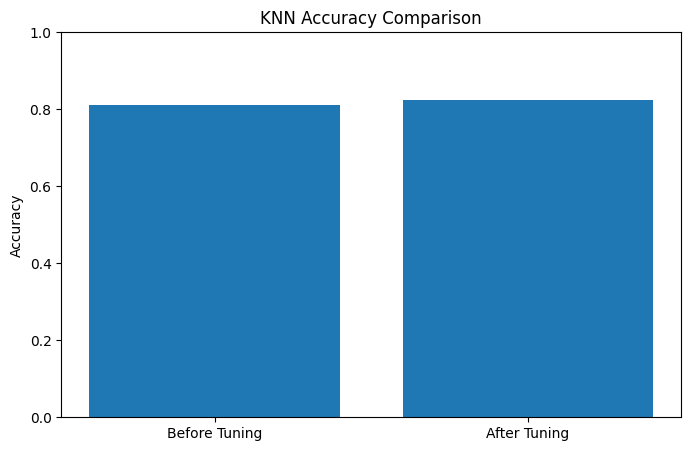

In [11]:
# 튜닝 전 평균 Accuracy
before_accuracy = scores.mean()

# 튜닝 후 최고 Accuracy
after_accuracy = grid_search.best_score_

# 결과 출력
print("========== 모델 성능 비교 ==========")

print(f"튜닝 전 Accuracy: {before_accuracy:.4f}")

print(f"튜닝 후 Accuracy: {after_accuracy:.4f}")

print(f"성능 변화: {(after_accuracy - before_accuracy):.4f}")

# 그래프
plt.figure(figsize=(8, 5))

plt.bar(
    ['Before Tuning', 'After Tuning'],
    [before_accuracy, after_accuracy]
)

plt.title('KNN Accuracy Comparison')
plt.ylabel('Accuracy')
plt.ylim(0, 1)

plt.show()

# 9. 최종 결과 및 해석

In [12]:
# 최적 모델
best_model = grid_search.best_estimator_

print("========== 최종 모델 결과 ==========")

print("최적 파라미터:")
print(grid_search.best_params_)

print(f"\n최종 Accuracy: {grid_search.best_score_:.4f}")

print("\n========== 최종 결과 해석 ==========")

if after_accuracy > before_accuracy:
    print("1. 하이퍼파라미터 튜닝 후 모델 성능이 향상되었습니다.")

elif after_accuracy == before_accuracy:
    print("1. 하이퍼파라미터 튜닝 전후 성능이 동일합니다.")

else:
    print("1. 하이퍼파라미터 튜닝 후 모델 성능이 낮아졌습니다.")

print(f"2. 튜닝 전 Accuracy는 {before_accuracy:.4f}입니다.")

print(f"3. 튜닝 후 Accuracy는 {after_accuracy:.4f}입니다.")

print("4. GridSearchCV를 통해 최적의 KNN 파라미터를 탐색했습니다.")

print("5. StratifiedKFold를 사용하여 생존자 비율을 유지하며 평가했습니다.")

========== 최종 모델 결과 ==========
최적 파라미터:
{'knn__n_neighbors': 7, 'knn__p': 1, 'knn__weights': 'uniform'}

최종 Accuracy: 0.8249

========== 최종 결과 해석 ==========
1. 하이퍼파라미터 튜닝 후 모델 성능이 향상되었습니다.
2. 튜닝 전 Accuracy는 0.8114입니다.
3. 튜닝 후 Accuracy는 0.8249입니다.
4. GridSearchCV를 통해 최적의 KNN 파라미터를 탐색했습니다.
5. StratifiedKFold를 사용하여 생존자 비율을 유지하며 평가했습니다.
